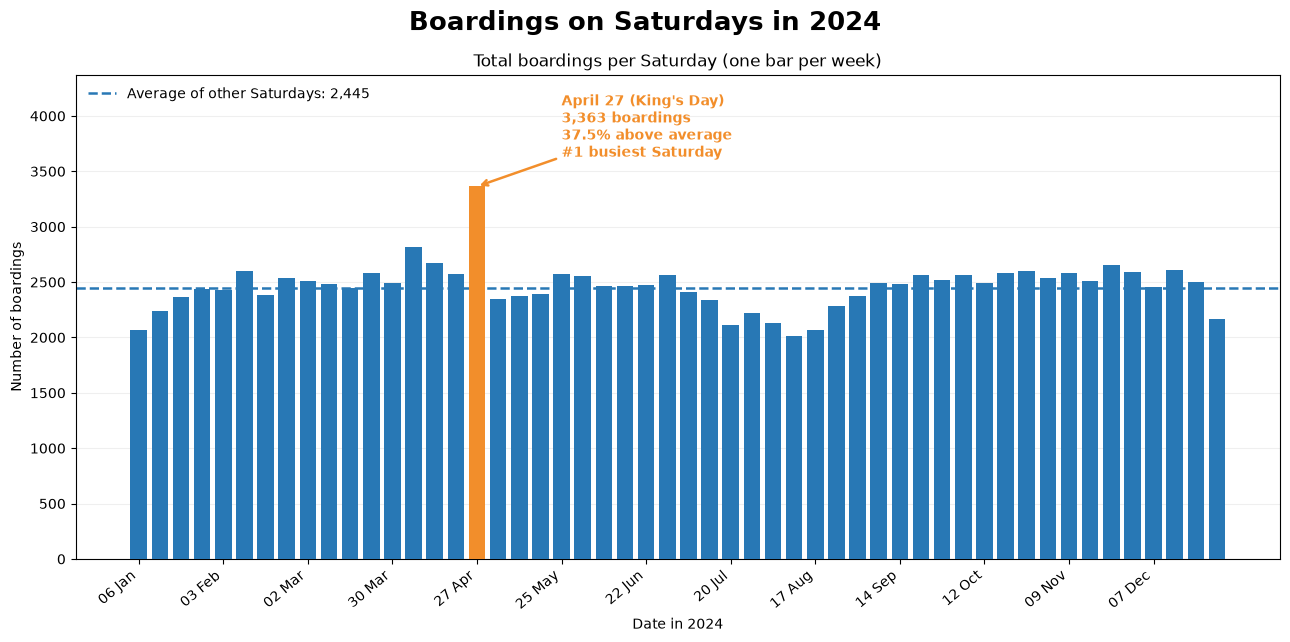

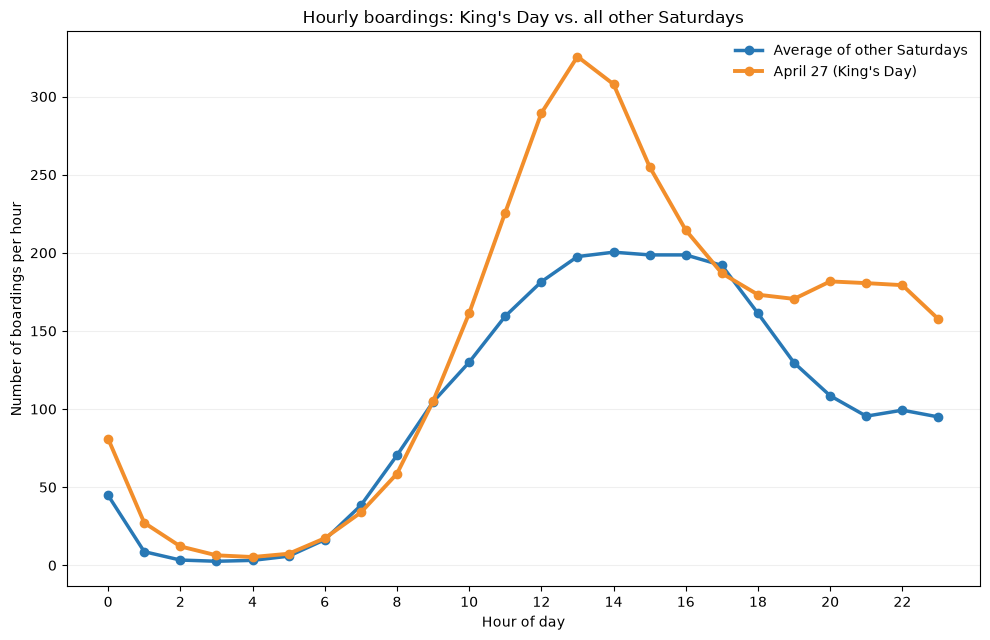

Saturdays: 52 | April 27: 3,363.2 boardings | average of other Saturdays: 2,445.3 | difference: +37.5% | rank: 1 of 52


In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Laad de CSV vanuit de projectmap.
csv_path = Path.cwd() / "Gefilterde datasets" / "Instappers_per_uur_export_V3_2024.csv"
if not csv_path.is_file():
    raise FileNotFoundError(
        f"CSV niet gevonden: {csv_path}. "
        "Open de notebook vanuit de projectmap."
    )

# De CSV heeft een afwijkende kopregel en een aanhalingsteken bij de laatste waarde.
df = pd.read_csv(
    csv_path,
    skiprows=1,
    names=["Datum", "Uur", "Aantal_check_ins"],
    quoting=csv.QUOTE_NONE,
)
df["Datum"] = pd.to_datetime(df["Datum"], format="%d-%m-%Y")
df["Uur"] = pd.to_numeric(df["Uur"])
df["Aantal_check_ins"] = pd.to_numeric(
    df["Aantal_check_ins"].astype(str).str.strip('"')
)

# Selecteer alleen zaterdagen en tel de uren per datum op.
zaterdagen = df.loc[df["Datum"].dt.dayofweek == 5].copy()
weektotalen = (
    zaterdagen.groupby("Datum")["Aantal_check_ins"]
    .sum()
    .sort_index()
)
koningsdag = pd.Timestamp("2024-04-27")
if koningsdag not in weektotalen.index:
    raise ValueError("27 april 2024 ontbreekt in de dataset.")

blauw = "#2878B5"
oranje = "#F28E2B"
gemiddelde = weektotalen.drop(koningsdag).mean()
koningsdag_totaal = weektotalen.loc[koningsdag]
procent_boven_gemiddelde = (koningsdag_totaal / gemiddelde - 1) * 100
rang = int(weektotalen.rank(ascending=False, method="min").loc[koningsdag])

# Vergelijk de verdeling per uur met alle zaterdagen, behalve Koningsdag.
andere_zaterdagen = zaterdagen.loc[zaterdagen["Datum"].ne(koningsdag)]
gemiddelde_per_uur = (
    andere_zaterdagen.groupby(["Datum", "Uur"])["Aantal_check_ins"]
    .sum()
    .groupby("Uur")
    .mean()
)
koningsdag_per_uur = (
    zaterdagen.loc[zaterdagen["Datum"].eq(koningsdag)]
    .set_index("Uur")["Aantal_check_ins"]
    .sort_index()
)

fig_week, ax_week = plt.subplots(figsize=(13, 6.5))
fig_week.suptitle("Boardings on Saturdays in 2024", fontsize=19, fontweight="bold")

# Daily total per Saturday; King's Day is highlighted in orange.
kleuren = [oranje if datum == koningsdag else blauw for datum in weektotalen.index]
ax_week.bar(weektotalen.index, weektotalen.values, color=kleuren, width=5.5, zorder=3)
ax_week.axhline(
    gemiddelde,
    color=blauw,
    linestyle="--",
    linewidth=1.8,
    label=f"Average of other Saturdays: {gemiddelde:,.0f}",
)
ax_week.annotate(
    f"April 27 (King's Day)\n{koningsdag_totaal:,.0f} boardings\n"
    f"{procent_boven_gemiddelde:.1f}% above average\n#{rang} busiest Saturday",
    xy=(koningsdag, koningsdag_totaal),
    xytext=(koningsdag + pd.Timedelta(days=28), koningsdag_totaal * 1.08),
    color=oranje,
    fontweight="bold",
    arrowprops={"arrowstyle": "->", "color": oranje, "lw": 1.8},
    ha="left",
)
ax_week.set_title("Total boardings per Saturday (one bar per week)")
ax_week.set_ylabel("Number of boardings")
ax_week.set_xlabel("Date in 2024")
month_abbreviations = ("Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec")
ax_week.set_xticks(weektotalen.index[::4])
ax_week.set_xticklabels(
    [f"{datum.day:02d} {month_abbreviations[datum.month - 1]}" for datum in weektotalen.index[::4]],
    rotation=40,
    ha="right",
)
ax_week.set_ylim(0, weektotalen.max() * 1.3)
ax_week.grid(axis="y", alpha=0.2, zorder=0)
ax_week.legend(frameon=False, loc="upper left")

fig_week.tight_layout()
fig_week.savefig(Path.cwd() / "boardings_per_saturday_2024.png", dpi=300, bbox_inches="tight")
plt.show()

# Right: compare hourly boardings on King's Day with all other Saturdays.
fig_hour, ax_hour = plt.subplots(figsize=(10, 6.5))
ax_hour.plot(
    gemiddelde_per_uur.index,
    gemiddelde_per_uur.values,
    color=blauw,
    marker="o",
    linewidth=2.5,
    label="Average of other Saturdays",
)
ax_hour.plot(
    koningsdag_per_uur.index,
    koningsdag_per_uur.values,
    color=oranje,
    marker="o",
    linewidth=2.8,
    label="April 27 (King's Day)",
)
ax_hour.set_title("Hourly boardings: King's Day vs. all other Saturdays")
ax_hour.set_xlabel("Hour of day")
ax_hour.set_ylabel("Number of boardings per hour")
ax_hour.set_xticks(range(0, 24, 2))
ax_hour.grid(axis="y", alpha=0.2)
ax_hour.legend(frameon=False)

fig_hour.tight_layout()
fig_hour.savefig(Path.cwd() / "hourly_boardings_kings_day_2024.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    f"Saturdays: {len(weektotalen)} | "
    f"April 27: {koningsdag_totaal:,.1f} boardings | "
    f"average of other Saturdays: {gemiddelde:,.1f} | "
    f"difference: +{procent_boven_gemiddelde:.1f}% | "
    f"rank: {rang} of {len(weektotalen)}"
)


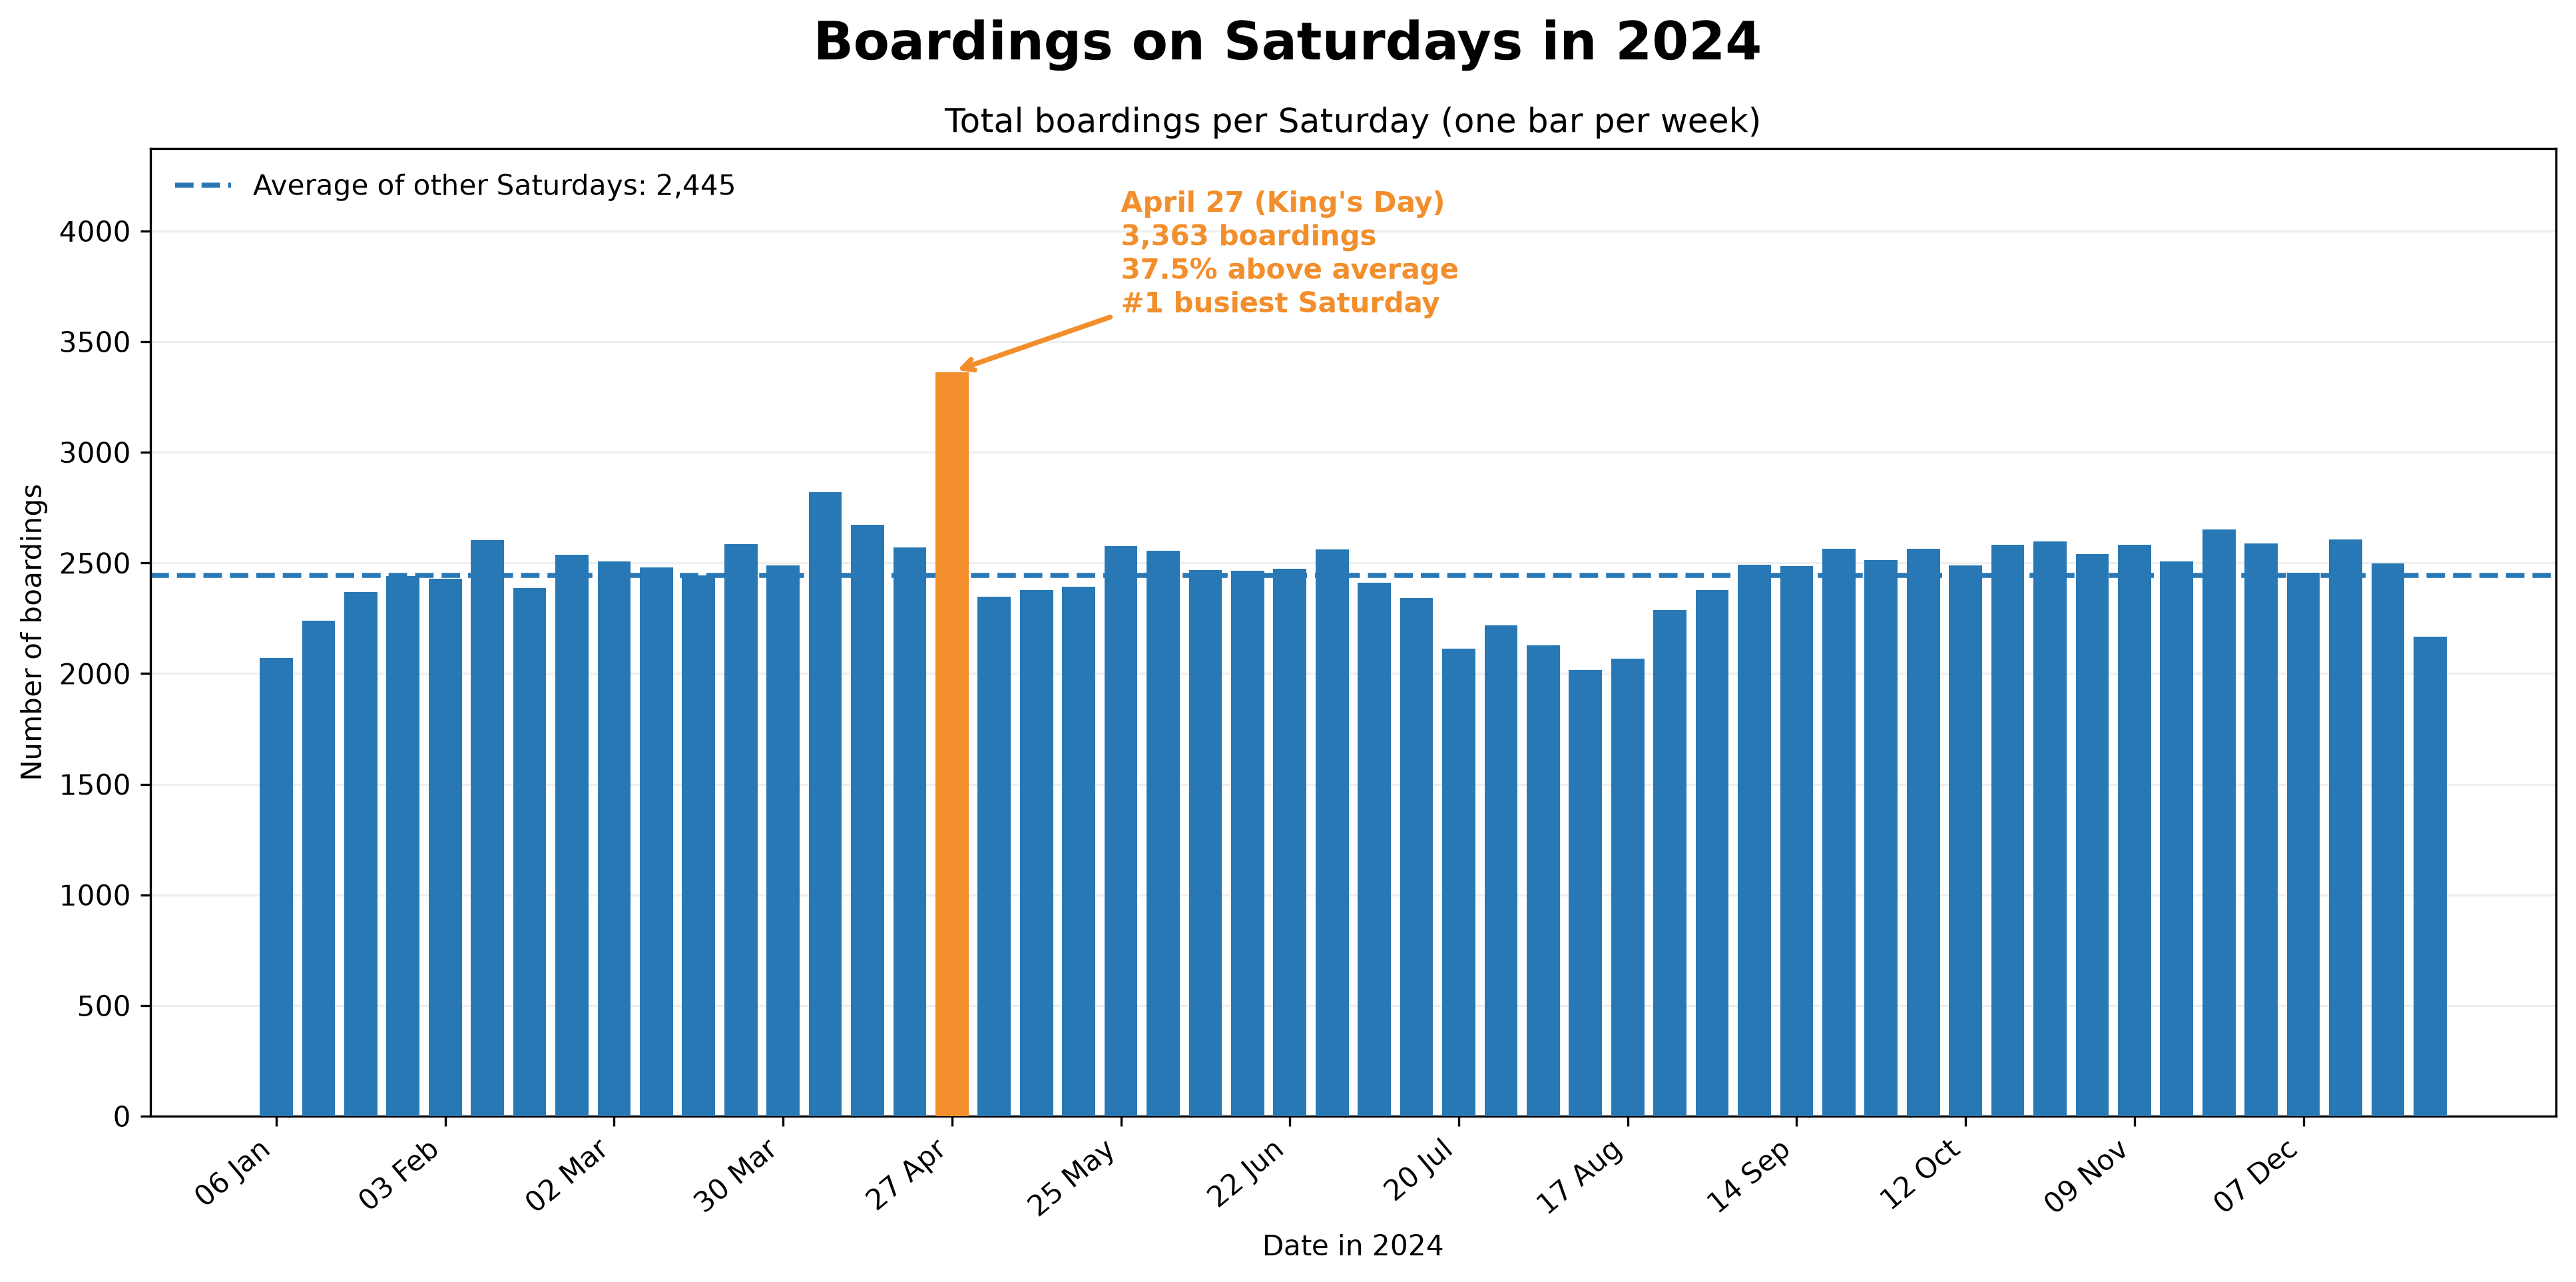

Displayed chart: boardings_per_saturday_2024.png


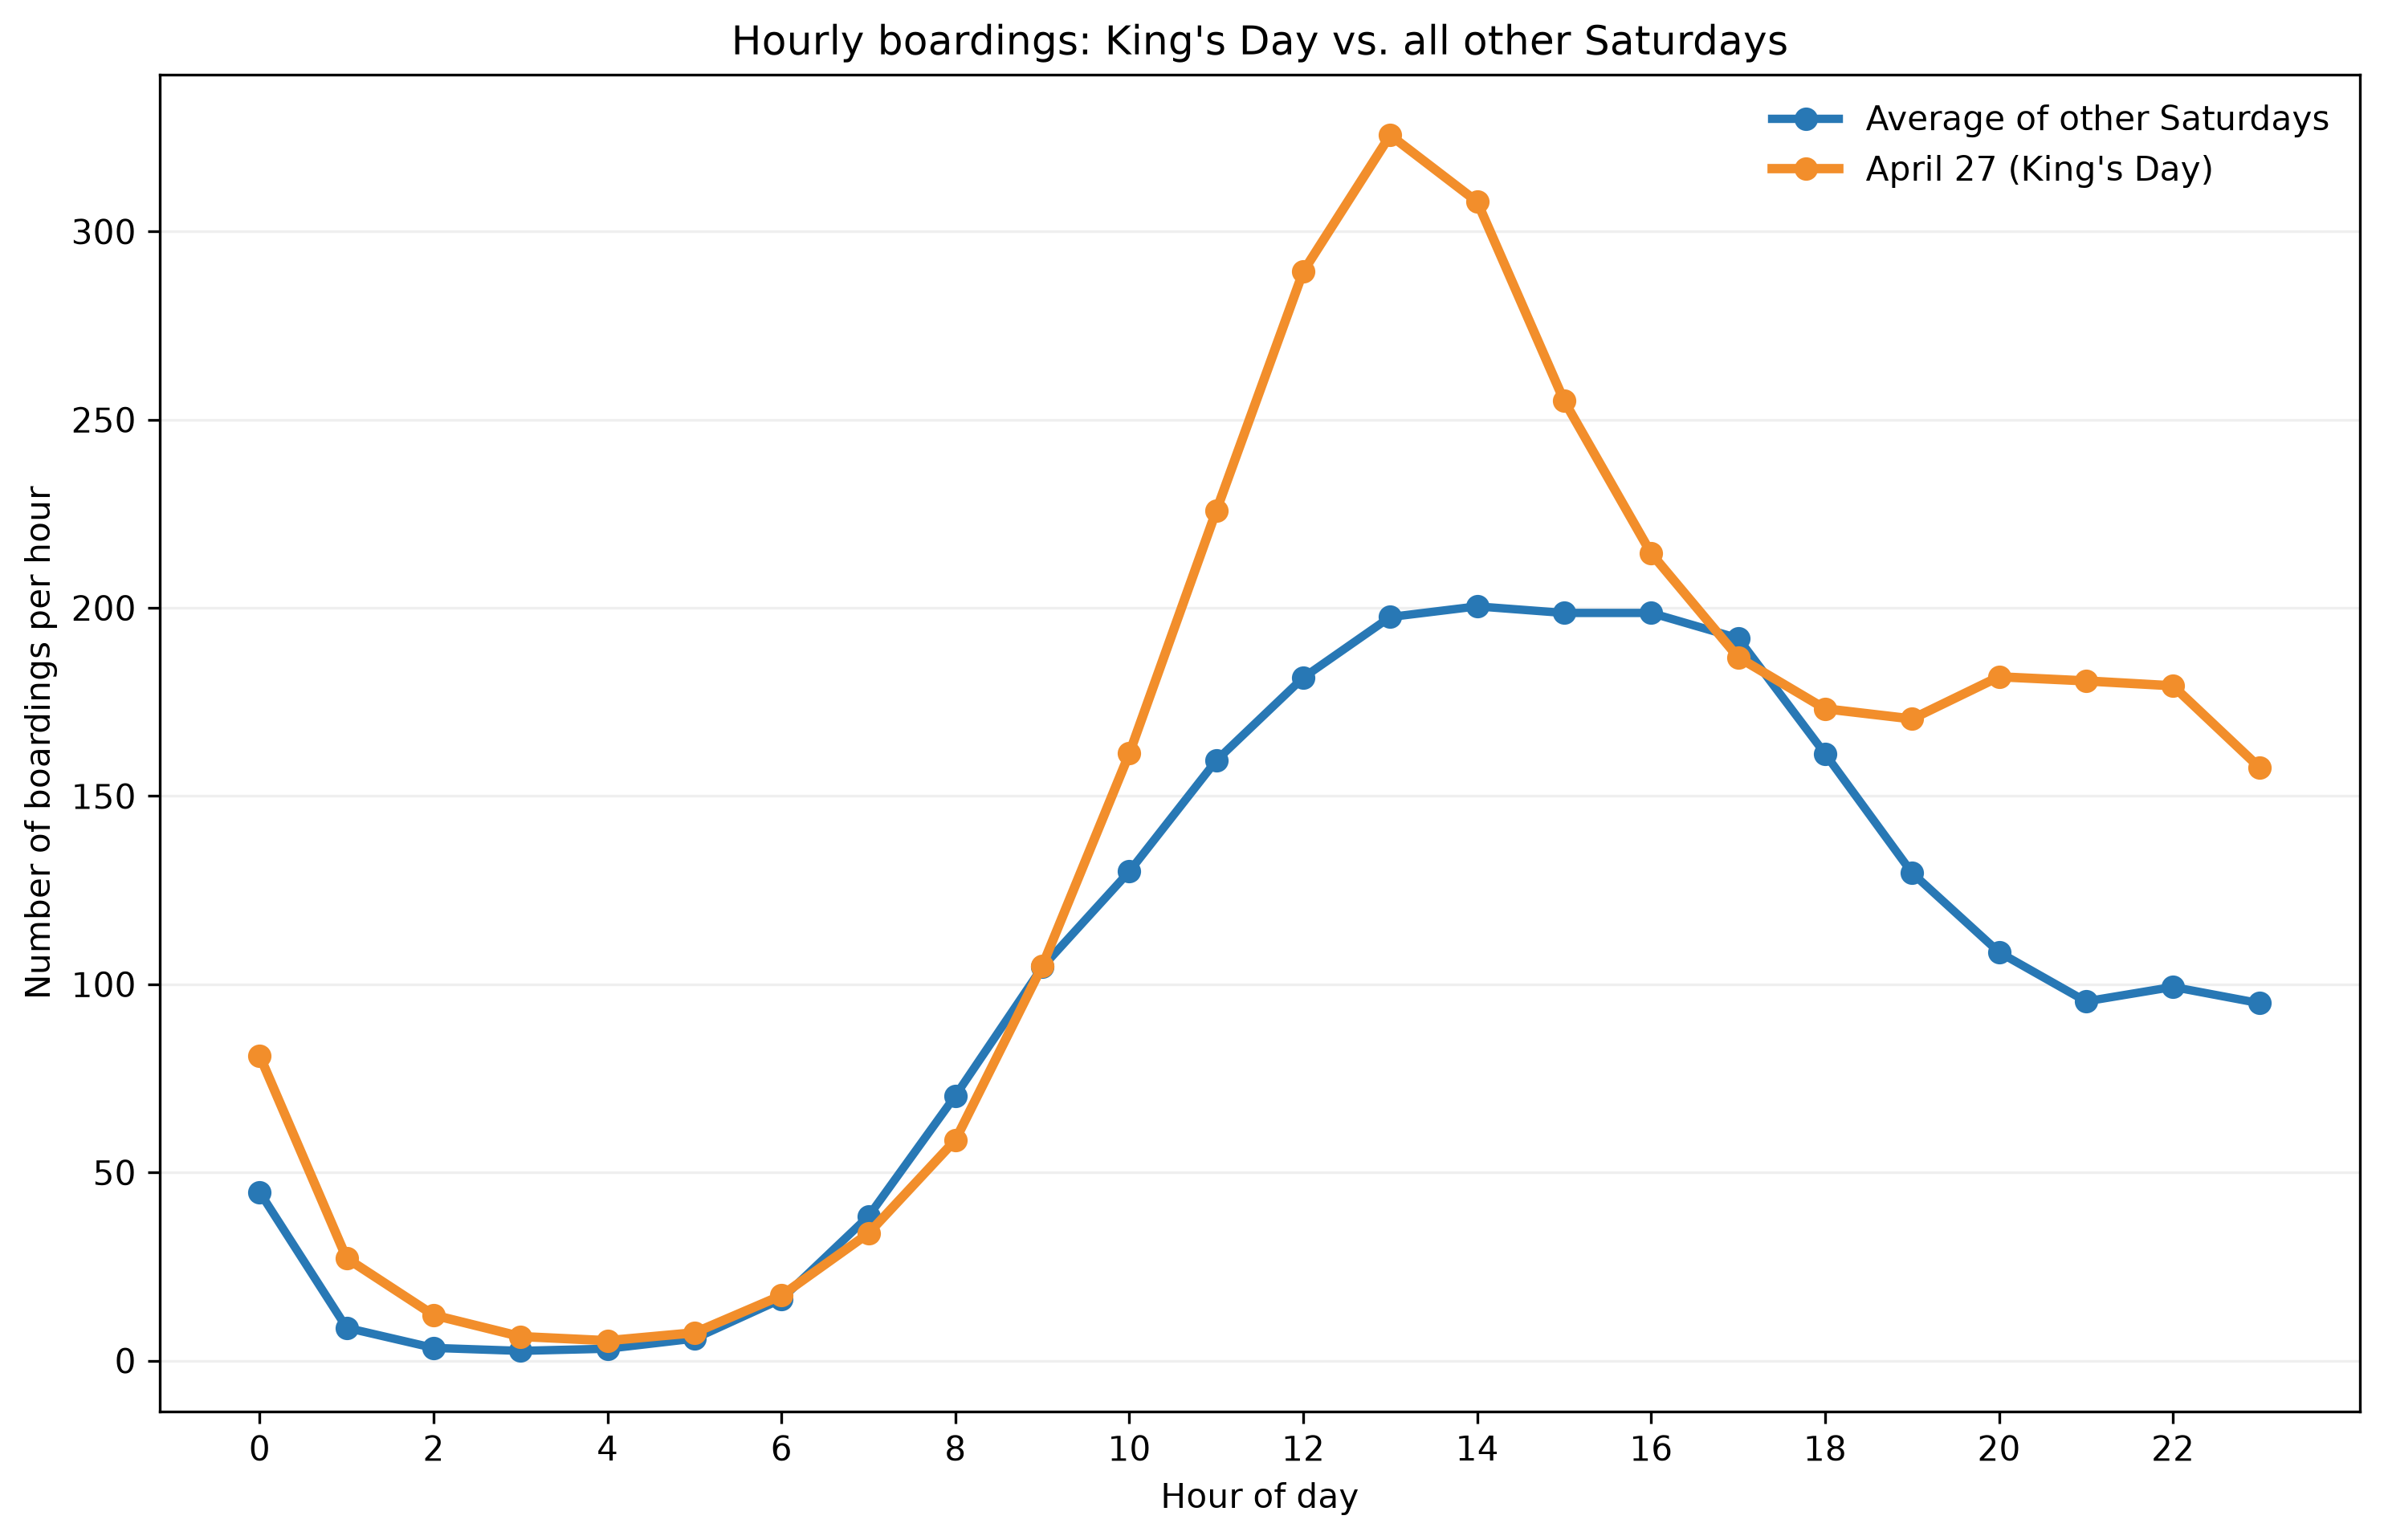

Displayed chart: hourly_boardings_kings_day_2024.png


In [2]:
from pathlib import Path
from PIL import Image
from IPython.display import display

project_dir = Path.cwd()
image_paths = [
    project_dir / 'boardings_per_saturday_2024.png',
    project_dir / 'hourly_boardings_kings_day_2024.png',
]

for image_path in image_paths:
    if not image_path.is_file():
        raise FileNotFoundError(f'Chart image not found: {image_path}')
    with Image.open(image_path) as image:
        display(image.copy())
    print(f'Displayed chart: {image_path.name}')
